# Linear clock missingness benchmark

Replicates the experiments from notebooks 03 and 04 on the **published linear regression clocks** (Horvath, Hannum, PhenoAge, GrimAge V2) rather than EpiHydra.

The held-out data is the same GEO test set never seen during EpiHydra training, so comparisons between this notebook and notebooks 03/04 are on the same samples.

Missingness is injected by setting CpG rows to `NaN` in the beta matrix before prediction. The clocks handle missing probes via built-in imputation (`impute_beta=0.5`).

**Key design choice:** all missingness metrics compare the masked prediction against the **zero-masking (baseline) prediction for the same sample**, not against chronological age. This isolates the degradation caused by missingness from each clock's inherent bias or offset relative to chronological age -- PhenoAge, for example, is designed to predict phenotypic rather than chronological age, so its MAE vs. chron age reflects its design intent, not its quality under missingness.

Requires `epigenetic_clocks.py` on the Python path.

## Parameters
Set everything here, then run all cells.

In [1]:
from pathlib import Path
import numpy as np

ROOT = Path("/work/gr-fe/bryan/EpiHydra")

# ── Held-out datasets (never seen during EpiHydra training) ───────
DATASET_IDS = ["GSE27097", "GSE40279", "GSE41037", "GSE42861"]
DATA_ROOT   = ROOT / "data/02_processed"

# ── Clock coefficient files ───────────────────────────────────────
COEF_ROOT    = ROOT / "data/03_final"
HORVATH_CSV  = COEF_ROOT / "Horvath/horvath.csv"
HANNUM_CSV   = COEF_ROOT / "Hannum/hannum.csv"
PHENOAGE_CSV = COEF_ROOT / "PhenoAge/phenoage.csv"
GRIMAGE_CSV  = COEF_ROOT / "GrimAge/GrimAgeV2.csv"

# Hannum intercept -- supply the correct value from the paper supplementary
HANNUM_INTERCEPT = 0.0   # update this

# ── Output ────────────────────────────────────────────────────────
SAVE_DIR = ROOT / "results/linear_clocks/missingness"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ── Analysis 1: synthetic random masking ──────────────────────────
# Same levels as notebooks 03/04 for direct comparison
MASK_FRACTIONS = np.round(np.arange(0.0, 1.0, 0.1), 2).tolist()
MASK_SEED      = 42

# ── Analysis 2: real coverage bins ───────────────────────────────
N_COVERAGE_BINS = 5
MIN_BIN_SAMPLES = 3

# ── Analysis 3: systematic probe removal ─────────────────────────
# "variance"   = least informative probes first
# "mean"       = most extreme methylation first
# "sequential" = sorted probe-ID order (positional baseline)
REMOVAL_STRATEGY  = "variance"
REMOVAL_FRACTIONS = MASK_FRACTIONS

## Imports

In [2]:
import pickle
import warnings
import sys

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
from sklearn.metrics import r2_score

%matplotlib inline

from methylgpt import MethylGPTModel, MethylVocab
from scgpt.tokenizer import tokenize_and_pad_batch, random_mask_value
import eval_utils as eu
sys.path.insert(0 , '../02_epiclocks/')
from epigenetic_clocks import (
    Horvath, Hannum, PhenoAge,
    GrimAgeV2, GrimAgeAdapter,
    run_all_clocks,
)

print("Imports OK")

Imports OK


## Load held-out datasets

Each GEO series is loaded from its own `methylation.pkl`. The CpG matrix is shaped
`(n_CpGs x n_samples)` with probe IDs as the index.

Completely NaN probes (never observed in any sample) are dropped; they carry no
information and would inflate apparent coverage.

In [3]:
dataset    = {}
chron_ages = {}
female     = {}

for gse in DATASET_IDS:
    with open(DATA_ROOT / gse / "methylation.pkl", "rb") as f:
        methylation = pickle.load(f)

    # Drop probes that are entirely unobserved across all samples
    cpg = methylation["CpG"].dropna(how="all")

    dataset[gse]    = cpg
    chron_ages[gse] = methylation["meta"].set_index("ID")["age"]
    female[gse]     = methylation["meta"].set_index("ID")["gender"] == "female"

    n_cpg, n_samp = cpg.shape
    lo, hi        = chron_ages[gse].min(), chron_ages[gse].max()
    pct_missing   = cpg.isna().values.mean() * 100
    print(f"{gse}: {n_samp} samples | {n_cpg:,} CpGs | "
          f"age {lo:.1f}-{hi:.1f} yrs | {pct_missing:.1f}% NaN")

GSE27097: 494 samples | 27,578 CpGs | age 3.6-17.8 yrs | 0.0% NaN
GSE40279: 656 samples | 473,034 CpGs | age 19.0-101.0 yrs | 0.0% NaN
GSE41037: 720 samples | 27,578 CpGs | age 16.0-88.0 yrs | 0.0% NaN
GSE42861: 689 samples | 485,577 CpGs | age 18.0-70.0 yrs | 0.0% NaN


## Instantiate clocks

`GrimAgeAdapter` captures the per-dataset age and sex arrays so `run_all_clocks`
can call every clock with the same `predict(methylation, impute_missing, verbose)` signature.

In [4]:
horvath  = Horvath(coefficients_path=HORVATH_CSV)
hannum   = Hannum(coefficients_path=HANNUM_CSV, intercept=HANNUM_INTERCEPT)
phenoage = PhenoAge(coefficients_path=PHENOAGE_CSV)
grimage  = GrimAgeAdapter(
    GrimAgeV2(coefficients_path=GRIMAGE_CSV),
    chron_ages = chron_ages,
    female     = female,
)

# Keyed dict so column names are explicit and consistent with notebooks 03/04
clocks = {
    "horvath_age"  : horvath,
    "hannum_age"   : hannum,
    "phenoage_age" : phenoage,
    "grimage_age"  : grimage,
}
clock_names = list(clocks.keys())
print("Clocks:", clock_names)

Loaded 353 CpG coefficients + intercept.
Loaded 71 CpG coefficients.
Loaded 513 CpG coefficients + intercept.
Loaded GrimAge V2: 10 sub-components, 1030 unique CpG probes.
Clocks: ['horvath_age', 'hannum_age', 'phenoage_age', 'grimage_age']


/tmp/4828274/ipykernel_3546040/3248900516.py:2: UserWarning: Hannum intercept is set to 0.0 (the default). This is almost certainly incorrect and will bias every prediction. Supply the correct value from the paper's supplementary materials.
  hannum   = Hannum(coefficients_path=HANNUM_CSV, intercept=HANNUM_INTERCEPT)


## Helper functions

These parallel the `eval_utils` equivalents (which operate on tokenised batches)
but work directly on beta-value DataFrames.

In [37]:
def _run_and_collect_raw(masked_datasets, clocks, chron_ages, clock_names, save_dir):
    """Run all clocks; return per-sample predictions as {clock: Series(id->pred)}."""
    raw_all = run_all_clocks(
        datasets       = masked_datasets,
        save_path      = save_dir,
        clocks         = clocks,
        chron_ages     = chron_ages,
        impute_missing = True,
        save_summary   = False,
        verbose        = False,
    )
    # Concatenate across datasets into one Series per clock
    result = {}
    for name in clock_names:
        parts = [age_df[name].dropna() for age_df in raw_all.values()]
        result[name] = pd.concat(parts)
    return result


def _compare_to_baseline(masked_datasets, baseline_preds, clocks, chron_ages,
                          clock_names, save_dir):
    """
    Run all clocks on masked_datasets and score each prediction against the
    BASELINE prediction (zero masking) for the same sample, not against
    chronological age.

    This isolates the effect of missingness from each clock's inherent
    bias or offset relative to chronological age.

    Returns pooled (preds, baseline_refs) per clock across all datasets,
    aligned on sample ID so only samples present in both are included.
    """
    masked_preds = _run_and_collect_raw(
        masked_datasets, clocks, chron_ages, clock_names, save_dir
    )
    preds        = {name: [] for name in clock_names}
    baseline_refs = {name: [] for name in clock_names}
    for name in clock_names:
        # Align on sample ID -- only score samples present in both
        common = masked_preds[name].index.intersection(baseline_preds[name].index)
        preds[name]         = masked_preds[name].loc[common].values
        baseline_refs[name] = baseline_preds[name].loc[common].values
    return (
        {n: np.array(v) for n, v in preds.items()},
        {n: np.array(v) for n, v in baseline_refs.items()},
    )


def mask_random_cpgs(dataset, mask_frac, rng):
    """Set a random fraction of probe rows to NaN across all datasets."""
    if mask_frac == 0.0:
        return dataset
    masked = {}
    for gse, cpg_df in dataset.items():
        n_remove  = max(1, int(len(cpg_df.index) * mask_frac))
        to_remove = rng.choice(cpg_df.index, size=n_remove, replace=False)
        df = cpg_df.copy()
        df.loc[to_remove] = np.nan
        masked[gse] = df
    return masked


def mask_systematic_cpgs(dataset, probes_to_remove):
    """Set specific probe rows to NaN in every dataset. Absent probes silently skipped."""
    if not probes_to_remove:
        return dataset
    masked = {}
    for gse, cpg_df in dataset.items():
        present = [p for p in probes_to_remove if p in cpg_df.index]
        df = cpg_df.copy()
        if present:
            df.loc[present] = np.nan
        masked[gse] = df
    return masked


def rank_cpgs_linear(dataset, strategy="variance"):
    """
    Rank CpG probes for systematic removal using the union of all datasets.

    strategy : 'variance'   -- remove lowest-variance probes first
               'mean'       -- remove lowest absolute mean probes first
               'sequential' -- remove in sorted probe-ID order (positional baseline)
    """
    all_probes = sorted(set().union(*[set(df.index) for df in dataset.values()]))

    if strategy == "sequential":
        return all_probes, "sequential (sorted probe ID order)"

    probe_vals = {}
    for cpg_df in dataset.values():
        for probe in cpg_df.index:
            vals = cpg_df.loc[probe].dropna().values.astype(float)
            probe_vals.setdefault(probe, [])
            probe_vals[probe].extend(vals.tolist())

    scores = {}
    for probe, vals in probe_vals.items():
        v = np.array(vals)
        v = v[np.isfinite(v)]
        if len(v) == 0:
            scores[probe] = np.nan
        elif strategy == "variance":
            scores[probe] = float(np.var(v))
        elif strategy == "mean":
            scores[probe] = float(np.mean(np.abs(v)))

    s = pd.Series(scores).dropna()
    if strategy == "variance":
        ranked = s.sort_values(ascending=True).index.tolist()
        label  = "ascending variance (least informative first)"
    else:
        ranked = s.sort_values(ascending=False).index.tolist()
        label  = "descending mean value (most extreme first)"

    unobserved = [p for p in all_probes if p not in s.index]
    return ranked + unobserved, label


def metrics_from_arrays(p, t):
    """Return (mae, pearson_r, r2). Returns NaN tuple if fewer than 2 samples."""
    n = len(p)
    if n < 2:
        return np.nan, np.nan, np.nan
    mae = float(np.mean(np.abs(p - t)))
    r   = float(pearsonr(p, t)[0]) if np.std(p) > 0 and np.std(t) > 0 else np.nan
    r2  = float(r2_score(t, p))    if np.std(p) > 0 else np.nan
    return mae, r, r2

## Baseline predictions (zero masking)

Runs all clocks with no extra missingness to establish the reference predictions.
All subsequent analyses score masked predictions **against these baseline predictions**
rather than against chronological age, so we measure how much missingness degrades
each clock's own output independently of its inherent offset from chronological age.

MAE / r / R² against chronological age are also shown for context, but are not used
in the missingness analyses.

In [38]:
# baseline_preds: {clock_name: Series(sample_id -> predicted_age)}
# Stored with sample IDs so masked runs can be aligned on ID before scoring.
baseline_preds = _run_and_collect_raw(
    dataset, clocks, chron_ages, clock_names,
    save_dir = SAVE_DIR / "baseline",
)

# Report performance vs. chronological age for context only
baseline_rows = []
for name in clock_names:
    p   = baseline_preds[name]
    # Align chronological ages to prediction index
    all_chron = pd.concat([chron_ages[gse] for gse in DATASET_IDS])
    t   = all_chron.reindex(p.index).dropna()
    p_a = p.loc[t.index].values
    mae, r, r2 = metrics_from_arrays(p_a, t.values)
    baseline_rows.append({
        "clock"    : name,
        "n"        : len(p_a),
        "mae_vs_chron"      : round(mae, 3),
        "pearson_r_vs_chron": round(r, 3),
        "r2_vs_chron"       : round(r2, 3),
    })

baseline = pd.DataFrame(baseline_rows).set_index("clock")
print("Baseline clock performance vs. chronological age (context only)")
display(baseline)

Baseline clock performance vs. chronological age (context only)


,n,mae_vs_chron,pearson_r_vs_chron,r2_vs_chron
clock,,,,
horvath_age,2463,3.879,0.973,0.945
hannum_age,2463,22.176,0.341,-0.852
phenoage_age,2463,9.636,0.941,0.705
grimage_age,2463,44.496,-0.263,-5.754


In [34]:
baseline_preds

{'horvath_age': array([ 5.57538006, 16.25775254,  7.0279574 , ..., 45.49012898,
        63.55868843, 37.7738973 ]),
 'hannum_age': array([64.7050902 , 66.6596745 , 64.9756309 , ..., 50.72809779,
        71.056376  , 42.60913104]),
 'phenoage_age': array([-23.20205301,  -1.51667408, -25.87535886, ...,  37.53152942,
         56.09967815,  30.59214683]),
 'grimage_age': array([ 96.49316337, 101.31357481,  95.5804818 , ...,  55.86071409,
         76.74646767,  49.88607427])}

## Analysis 1 — Synthetic random masking

For each masking fraction, a random subset of probe rows is set to `NaN` before
prediction. The clocks impute the missing value at `beta=0.5`. The same seed is
used at every fraction so variation reflects masking level only.

Metrics are computed by comparing the **masked prediction** against the
**zero-masking (baseline) prediction for the same sample**. MAE here measures
how far the clock shifts from its own best answer, not from chronological age.

In [7]:
rand_rows = []

for frac in MASK_FRACTIONS:
    rng           = np.random.default_rng(MASK_SEED)   # same seed every fraction
    masked_data   = mask_random_cpgs(dataset, frac, rng)
    preds, refs   = _compare_to_baseline(
        masked_data, baseline_preds, clocks, chron_ages, clock_names,
        save_dir = SAVE_DIR / "masking_tmp",
    )
    for name in clock_names:
        p, t = preds[name], refs[name]
        mae, r, r2 = metrics_from_arrays(p, t)
        rand_rows.append(dict(clock=name, mask_frac=frac,
                              mae=mae, pearson_r=r, r2=r2, n=len(p)))
    print(f"  frac={frac:.1f} done")

mask_results = pd.DataFrame(rand_rows)
display(mask_results.round(3))

  frac=0.0 done
  frac=0.1 done
  frac=0.2 done
  frac=0.3 done
  frac=0.4 done
  frac=0.5 done
  frac=0.6 done
  frac=0.7 done
  frac=0.8 done
  frac=0.9 done


,clock,mask_frac,mae,pearson_r,r2,n
0,horvath_age,0.0,0.000,1.000,1.000,2559
1,hannum_age,0.0,0.000,1.000,1.000,2559
2,phenoage_age,0.0,0.000,1.000,1.000,2559
3,grimage_age,0.0,0.000,1.000,1.000,2463
4,horvath_age,0.1,26.322,-0.058,-1.547,2559
5,hannum_age,0.1,4.445,0.882,0.354,2559
6,phenoage_age,0.1,45.101,0.738,-3.463,2559
7,grimage_age,0.1,11.848,0.943,0.585,2463
8,horvath_age,0.2,36.856,-0.310,-3.264,2559
9,hannum_age,0.2,5.483,0.898,0.491,2559


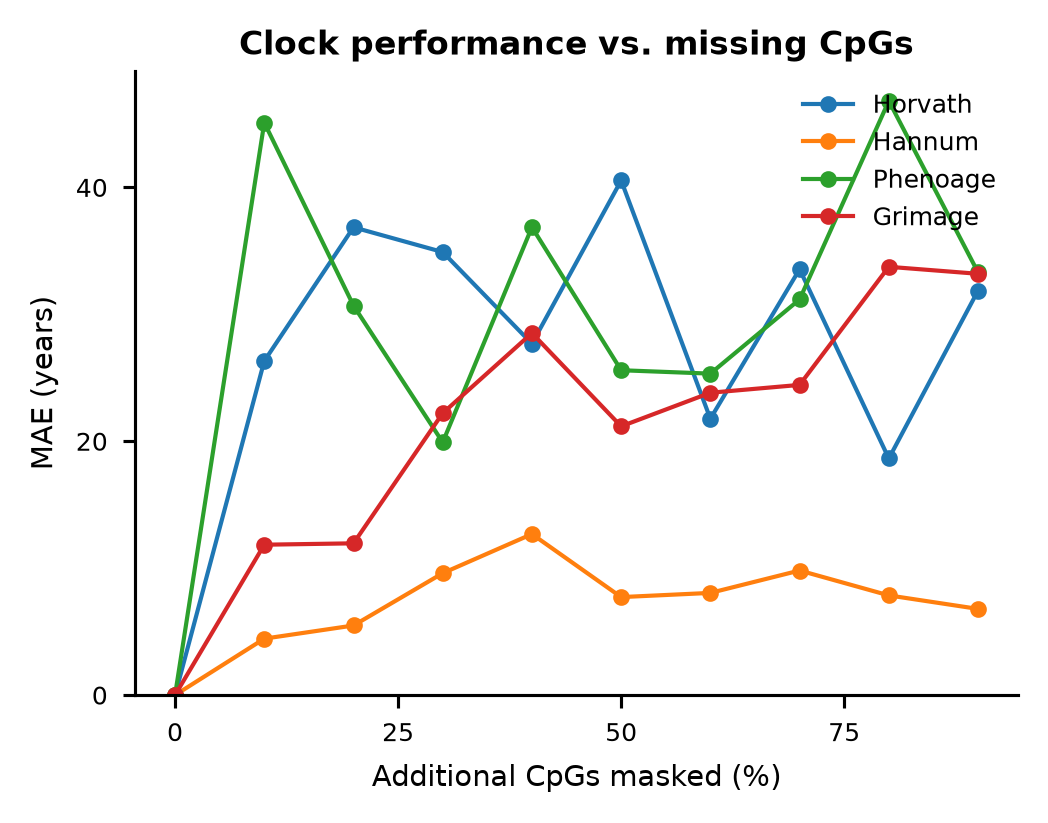

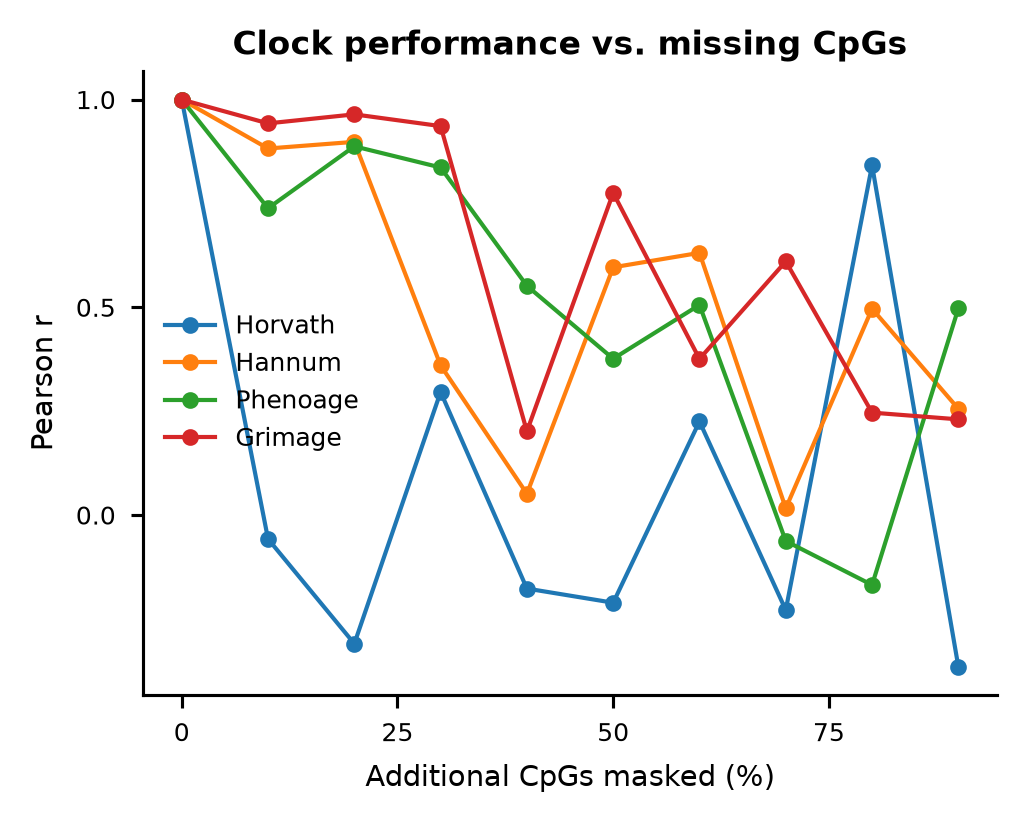

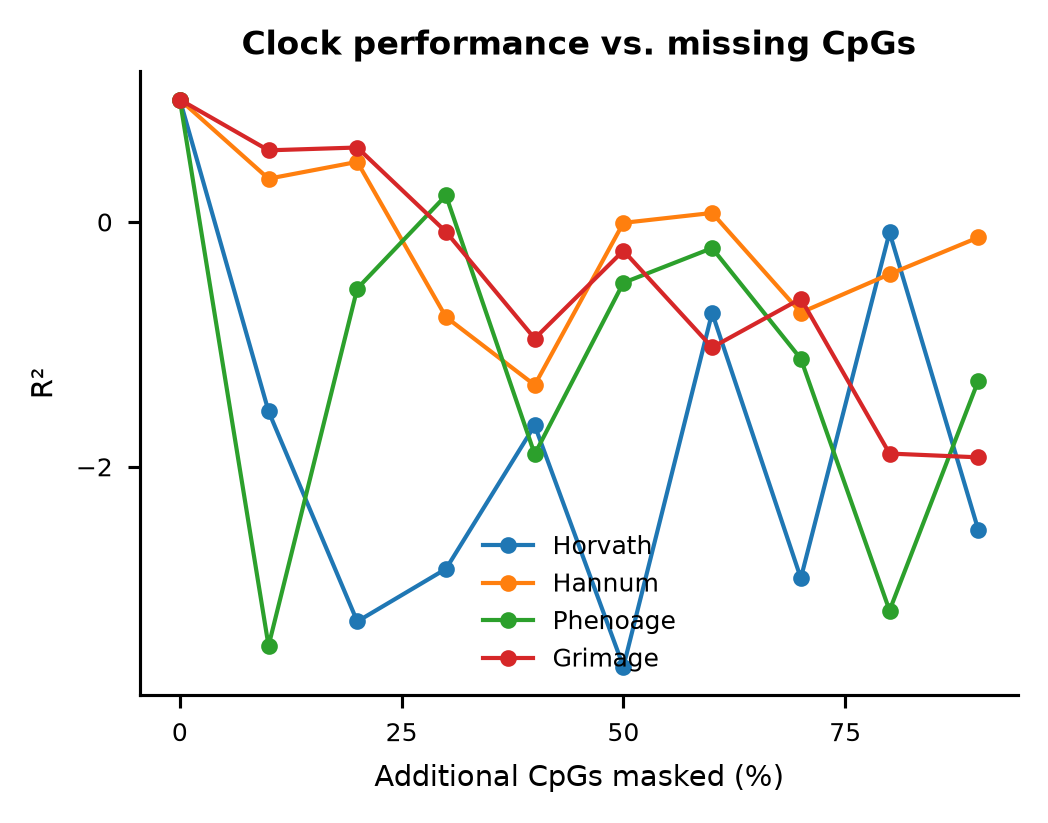

In [8]:
for metric in ("mae", "pearson_r", "r2"):
    fig, ax = eu.plot_missing_fraction_curves(mask_results, metric=metric,
                                              clock_names=clock_names)
    if SAVE_DIR:
        fig.savefig(SAVE_DIR / f"masking_curve_{metric}.pdf")
        fig.savefig(SAVE_DIR / f"masking_curve_{metric}.png")
    plt.show()

## Analysis 2 — Real CpG coverage bins

Each sample is grouped by its actual observed CpG coverage fraction and per-clock
performance is computed within each bin.

As with Analysis 1, the reference is each sample's **baseline prediction** (zero
masking), so the metric captures how much real probe missingness shifts the clock
from its own best answer.

In [9]:
# Build per-sample coverage from the actual beta matrices
coverage_parts = []
for gse, cpg_df in dataset.items():
    cov_df = cpg_df.notna().mean(axis=0).rename("cpg_coverage").to_frame()
    cov_df.index.name = "ID"
    cov_df["dataset"]   = gse
    cov_df["chron_age"] = chron_ages[gse].reindex(cov_df.index)
    coverage_parts.append(cov_df)

coverage_df = pd.concat(coverage_parts)
print("Coverage distribution (all datasets):")
print(coverage_df["cpg_coverage"].describe().round(3))

Coverage distribution (all datasets):
count    2559.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: cpg_coverage, dtype: float64


In [12]:
# Run baseline predictions dataset-by-dataset to keep sample IDs for the join
pred_frames = []
for gse, cpg_df in dataset.items():
    raw = run_all_clocks(
        datasets       = {gse: cpg_df},
        save_path      = SAVE_DIR / "coverage_tmp",
        clocks         = clocks,
        chron_ages     = chron_ages,
        impute_missing = True,
        save_summary   = False,
        verbose        = False,
    )[gse]
    raw["dataset"] = gse
    pred_frames.append(raw)

all_preds_df = pd.concat(pred_frames)

# _true = baseline prediction for the same sample (not chronological age)
predictions_cov = pd.DataFrame(index=all_preds_df.index)
predictions_cov["dataset"] = all_preds_df["dataset"]
for name in clock_names:
    predictions_cov[name + "_pred"] = all_preds_df[name]
    predictions_cov[name + "_true"] = baseline_preds[name].reindex(all_preds_df.index)

In [13]:
coverage_results = eu.compute_coverage_performance(
    predictions_cov, coverage_df, clock_names,
    n_bins      = N_COVERAGE_BINS,
    min_samples = MIN_BIN_SAMPLES,
)
display(coverage_results.round(3))

,clock,coverage_bin,coverage_mid,mae,pearson_r,r2,n
0,horvath_age,80%–100%,0.9,0.0,1.0,1.0,2559
1,hannum_age,80%–100%,0.9,0.0,1.0,1.0,2559
2,phenoage_age,80%–100%,0.9,0.0,1.0,1.0,2559
3,grimage_age,80%–100%,0.9,0.0,1.0,1.0,2463


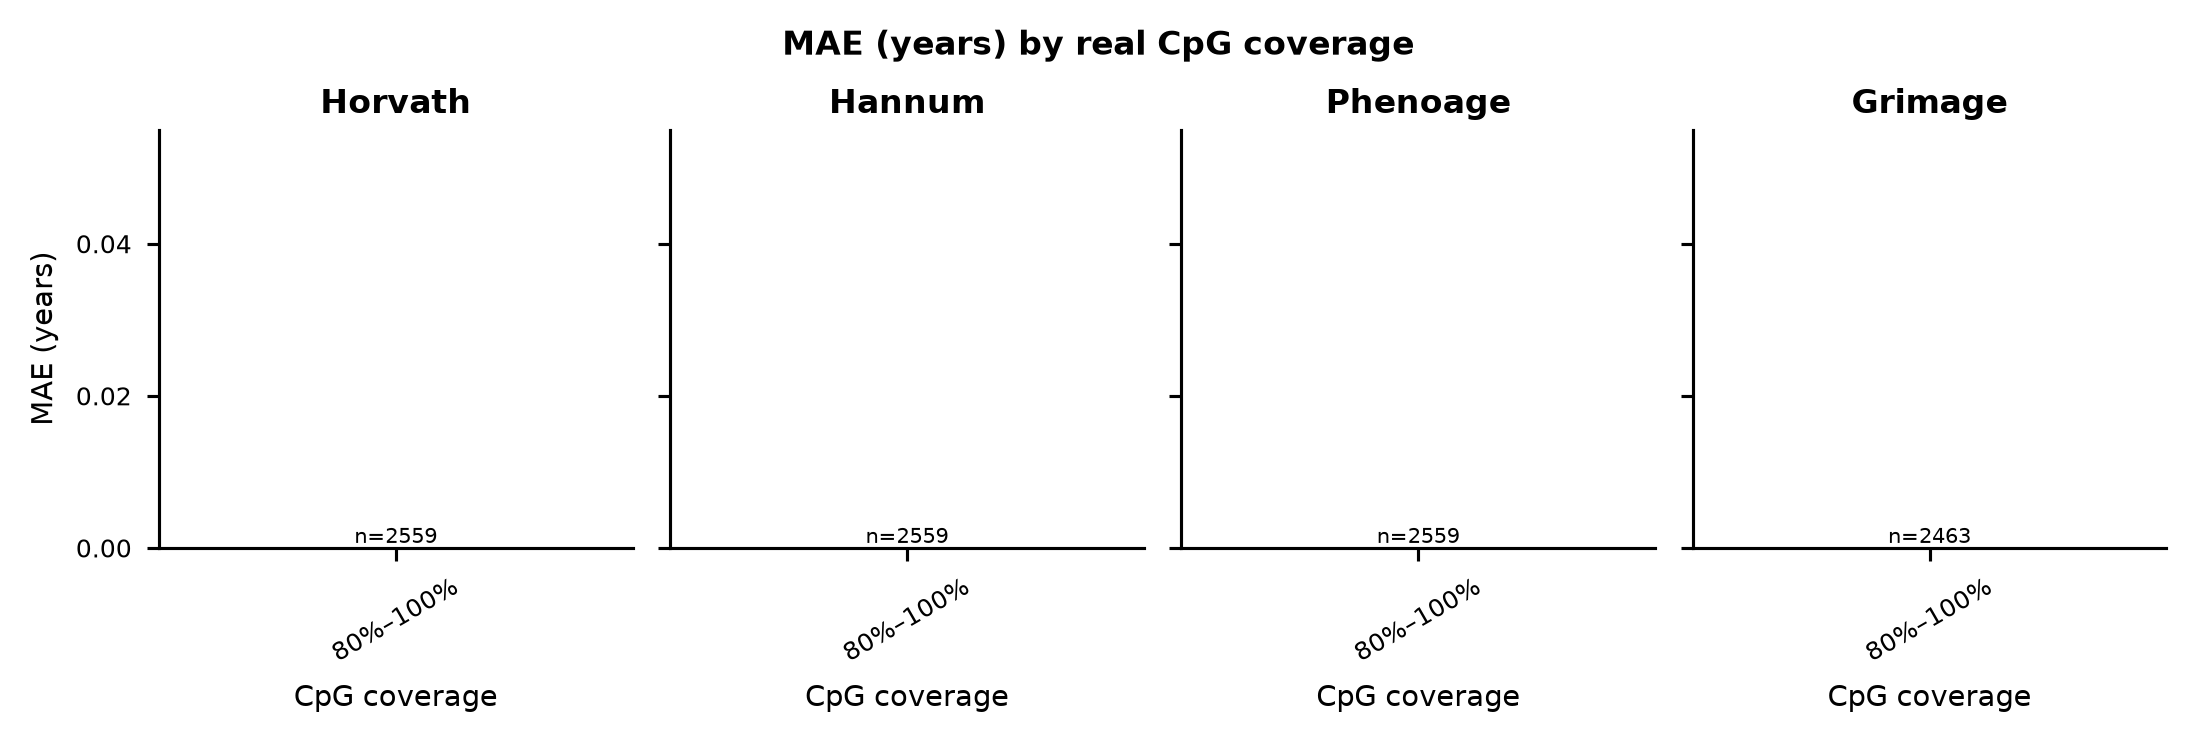

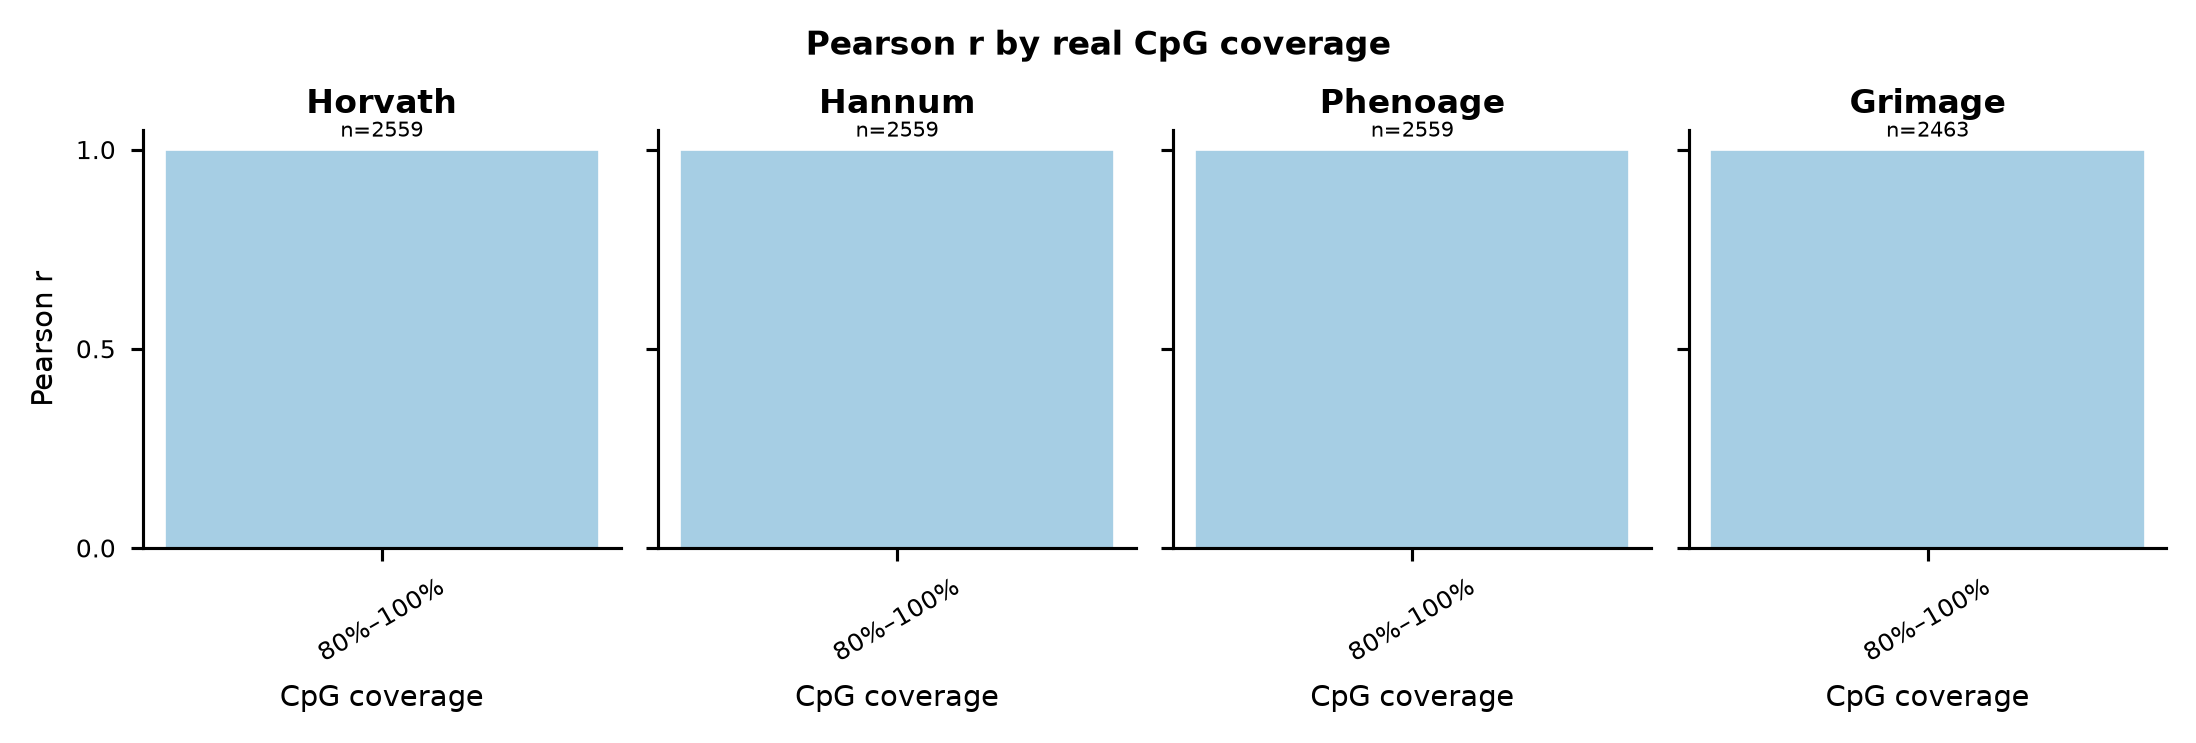

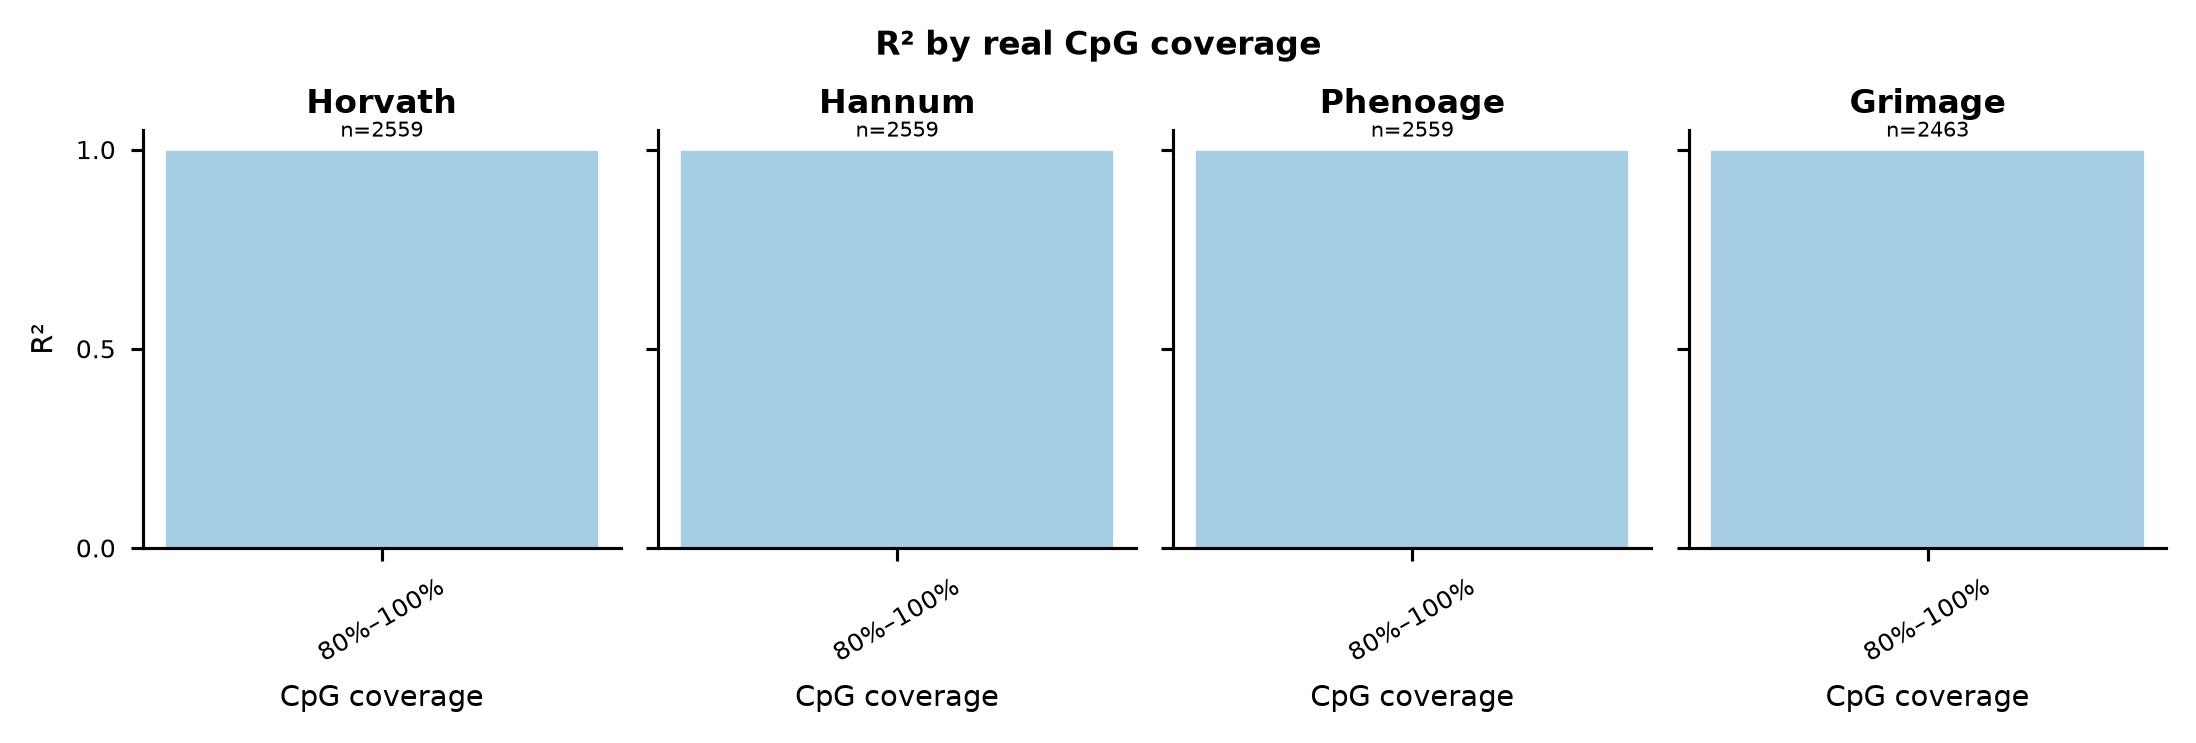

In [14]:
for metric in ("mae", "pearson_r", "r2"):
    fig, axes = eu.plot_coverage_performance(coverage_results, metric=metric,
                                             clock_names=clock_names)
    if SAVE_DIR:
        fig.savefig(SAVE_DIR / f"coverage_bins_{metric}.pdf")
        fig.savefig(SAVE_DIR / f"coverage_bins_{metric}.png")
    plt.show()

## Analysis 3 — Systematic probe removal

Removes the same CpGs from every sample simultaneously, ordered by `REMOVAL_STRATEGY`.
Simulates a whole-assay failure.

As with Analyses 1 and 2, masked predictions are scored against the **baseline
prediction for the same sample**, not against chronological age.

In [15]:
ranked_probes, strategy_label = rank_cpgs_linear(dataset, strategy=REMOVAL_STRATEGY)
n_total_probes = len(ranked_probes)
print(f"Strategy  : {strategy_label}")
print(f"Total CpGs: {n_total_probes:,}")
print(f"First 5 to remove: {ranked_probes[:5]}")

Strategy  : ascending variance (least informative first)
Total CpGs: 487,177
First 5 to remove: ['cg20530339', 'cg09705456', 'cg06743060', 'cg25410318', 'cg16706374']


In [16]:
syst_rows = []

for frac in REMOVAL_FRACTIONS:
    n_remove      = int(frac * n_total_probes)
    probes_off    = ranked_probes[:n_remove]
    masked_data   = mask_systematic_cpgs(dataset, probes_off)
    preds, refs   = _compare_to_baseline(
        masked_data, baseline_preds, clocks, chron_ages, clock_names,
        save_dir = SAVE_DIR / "removal_tmp",
    )
    for name in clock_names:
        p, t = preds[name], refs[name]
        mae, r, r2 = metrics_from_arrays(p, t)
        syst_rows.append(dict(clock=name, removal_frac=frac, n_removed=n_remove,
                              mae=mae, pearson_r=r, r2=r2, n=len(p)))
    print(f"  frac={frac:.1f} ({n_remove:,} probes removed) done")

systematic_results = pd.DataFrame(syst_rows)
display(systematic_results.round(3))

  frac=0.0 (0 probes removed) done
  frac=0.1 (48,717 probes removed) done
  frac=0.2 (97,435 probes removed) done
  frac=0.3 (146,153 probes removed) done
  frac=0.4 (194,870 probes removed) done
  frac=0.5 (243,588 probes removed) done
  frac=0.6 (292,306 probes removed) done
  frac=0.7 (341,023 probes removed) done
  frac=0.8 (389,741 probes removed) done
  frac=0.9 (438,459 probes removed) done


,clock,removal_frac,n_removed,mae,pearson_r,r2,n
0,horvath_age,0.0,0,0.000,1.000,1.000,2559
1,hannum_age,0.0,0,0.000,1.000,1.000,2559
2,phenoage_age,0.0,0,0.000,1.000,1.000,2559
3,grimage_age,0.0,0,0.000,1.000,1.000,2463
4,horvath_age,0.1,48717,7.915,0.998,0.840,2559
5,hannum_age,0.1,48717,0.000,1.000,1.000,2559
6,phenoage_age,0.1,48717,10.809,1.000,0.814,2559
7,grimage_age,0.1,48717,12.058,0.943,0.553,2463
8,horvath_age,0.2,97435,58.221,0.994,-7.296,2559
9,hannum_age,0.2,97435,0.000,1.000,1.000,2559


In [18]:
def plot_systematic_removal_curves(systematic_results, random_results=None,
                                   metric="mae", clock_names=None,
                                   strategy_label="systematic"):
    """
    Line plot of clock performance vs. fraction of probes systematically
    removed, one subplot per clock.
 
    If `random_results` (from evaluate_missing_fraction) is also passed, the
    random masking curve is overlaid as a dashed line for direct comparison —
    the gap between the two shows whether probe identity matters or whether
    any missing data hurts equally.
 
    Parameters
    ----------
    systematic_results : DataFrame from evaluate_systematic_removal
    random_results     : DataFrame from evaluate_missing_fraction, or None
    metric             : "mae", "pearson_r", or "r2"
    clock_names        : list[str] or None
    strategy_label     : str — used in the legend for the systematic line
    """
    if clock_names is None:
        clock_names = systematic_results["clock"].unique().tolist()
 
    high_is_good = metric in ("pearson_r", "r2")
    ylabel = {"mae": "MAE (years)", "pearson_r": "Pearson r", "r2": "R²"}[metric]
    n      = len(clock_names)
 
    with plt.rc_context(_NM_RC):
        fig_w = min(183, 55 * n) / 25.4
        fig, axes = plt.subplots(1, n, figsize=(fig_w, 65 / 25.4),
                                 sharey=True, constrained_layout=True)
        if n == 1:
            axes = [axes]
 
        cmap = plt.get_cmap("tab10")
 
        for ax, (i, name) in zip(axes, enumerate(clock_names)):
            color = cmap(i)
 
            sub = systematic_results[systematic_results["clock"] == name].sort_values("removal_frac")
            ax.plot(sub["removal_frac"] * 100, sub[metric],
                    marker="o", markersize=3, lw=1.0, color=color,
                    label=strategy_label)
 
            if random_results is not None:
                rsub = random_results[random_results["clock"] == name].sort_values("mask_frac")
                ax.plot(rsub["mask_frac"] * 100, rsub[metric],
                        marker="s", markersize=3, lw=1.0, color=color,
                        ls="--", alpha=0.6, label="random")
 
            ax.set_title(_clean(name), pad=4, fontweight="bold")
            ax.set_xlabel("CpGs removed (%)")
            if not high_is_good:
                ax.set_ylim(bottom=0)
            ax.legend(frameon=False, fontsize=5)
 
        axes[0].set_ylabel(ylabel)
        fig.suptitle(f"Systematic probe removal — {ylabel}",
                     fontsize=8, fontweight="bold")
 
    return fig, axes

# ─────────────────────────────────────────────────────────────────────────────
# Nature Medicine-style clock plots
# ─────────────────────────────────────────────────────────────────────────────
 
# Typographic / style constants matching NM figure conventions
_NM_RC = {
    # Font
    "font.family"        : "sans-serif",
    "font.sans-serif"    : ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size"          : 7,
    "axes.titlesize"     : 8,
    "axes.labelsize"     : 7,
    "xtick.labelsize"    : 6,
    "ytick.labelsize"    : 6,
    "legend.fontsize"    : 6,
    # Lines / markers
    "axes.linewidth"     : 0.75,
    "xtick.major.width"  : 0.75,
    "ytick.major.width"  : 0.75,
    "xtick.major.size"   : 3,
    "ytick.major.size"   : 3,
    "lines.linewidth"    : 1.0,
    # Layout
    "axes.spines.top"    : False,
    "axes.spines.right"  : False,
    "figure.dpi"         : 300,
    "savefig.dpi"        : 300,
    "savefig.bbox"       : "tight",
    "savefig.pad_inches" : 0.02,
}
 
# Colour palette
_SCATTER_FACE  = "#2166AC"   # blue fill
_SCATTER_EDGE  = "#1a1a1a"   # near-black edge
_IDENTITY_COL  = "#D6604D"   # red identity line
_REG_COL       = "#4D4D4D"   # dark-grey regression line

def _clean(name):
    """Strip common suffixes for axis / title labels."""
    return name.replace("_age", "").replace("_clock", "").replace("_", " ").title()
 
 
def _stat_annotation(ax, pearson_r, r2, mae, n, x=0.05, y=0.95):
    """
    Add a compact stats box in the upper-left corner, NM style (no box frame).
    """
    text = (
        f"r = {pearson_r:.2f}\n"
        f"R² = {r2:.2f}\n"
        f"MAE = {mae:.1f}\n"
        f"n = {n}"
    )
    ax.text(x, y, text, transform=ax.transAxes,
            fontsize=6, verticalalignment="top",
            linespacing=1.6, color="#1a1a1a")

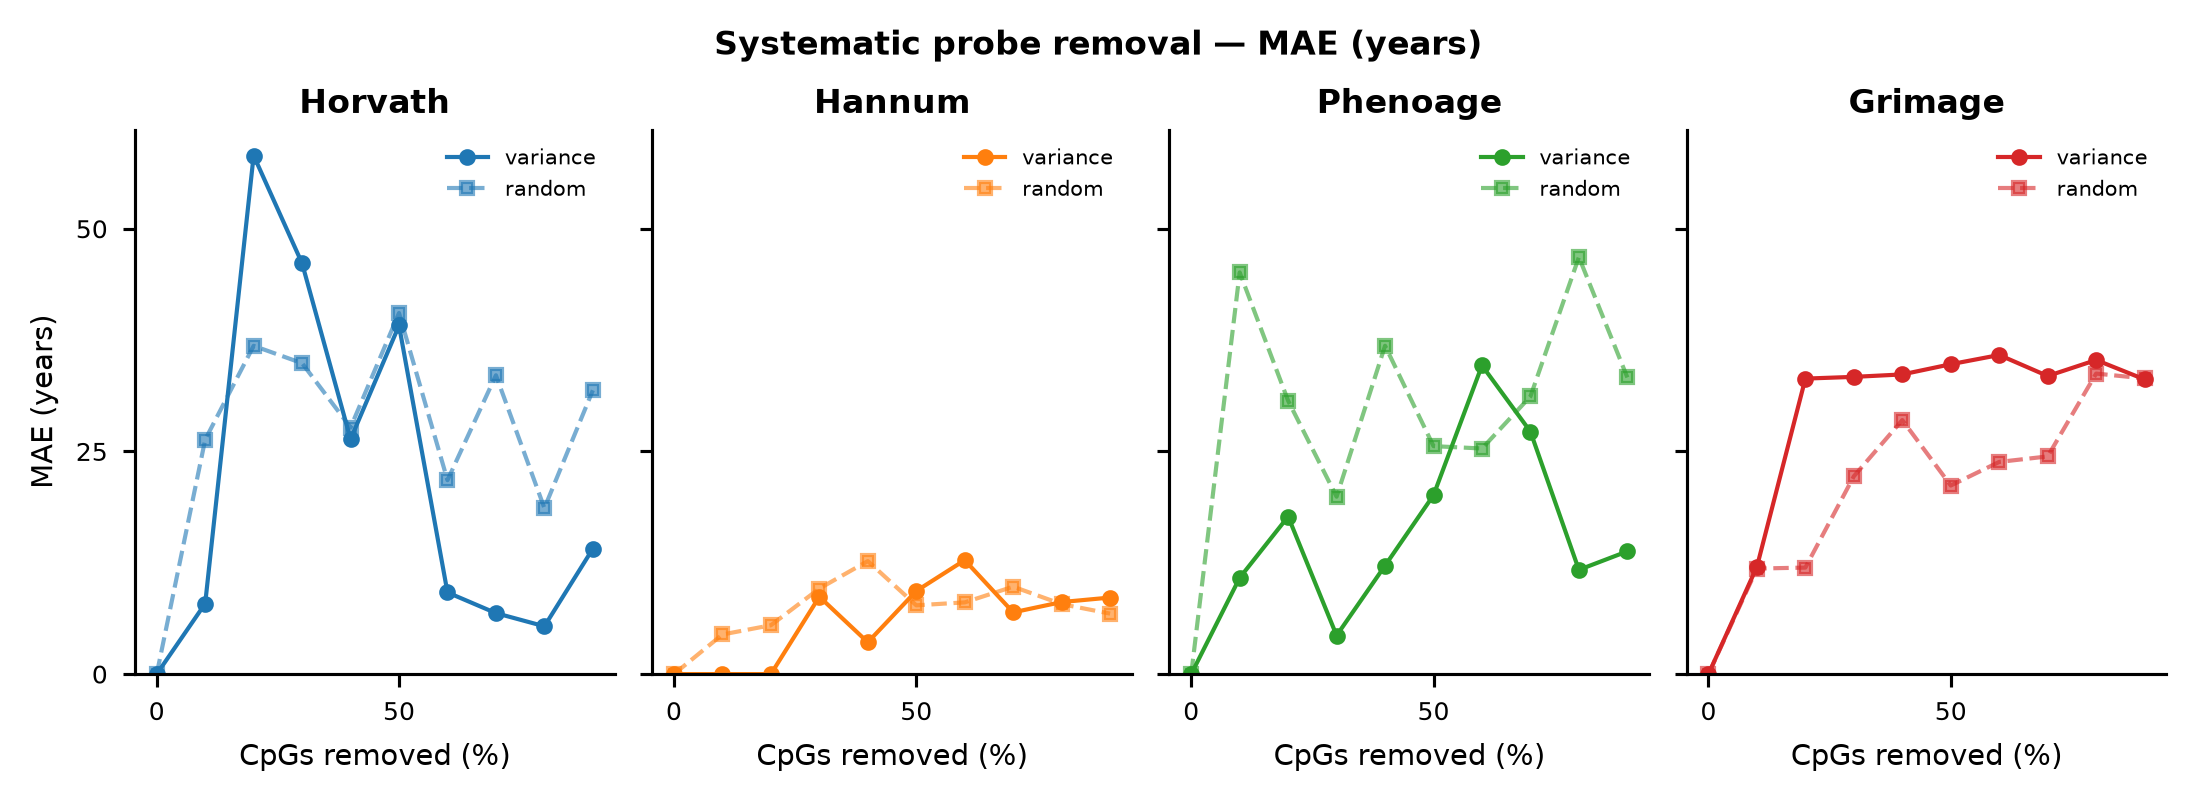

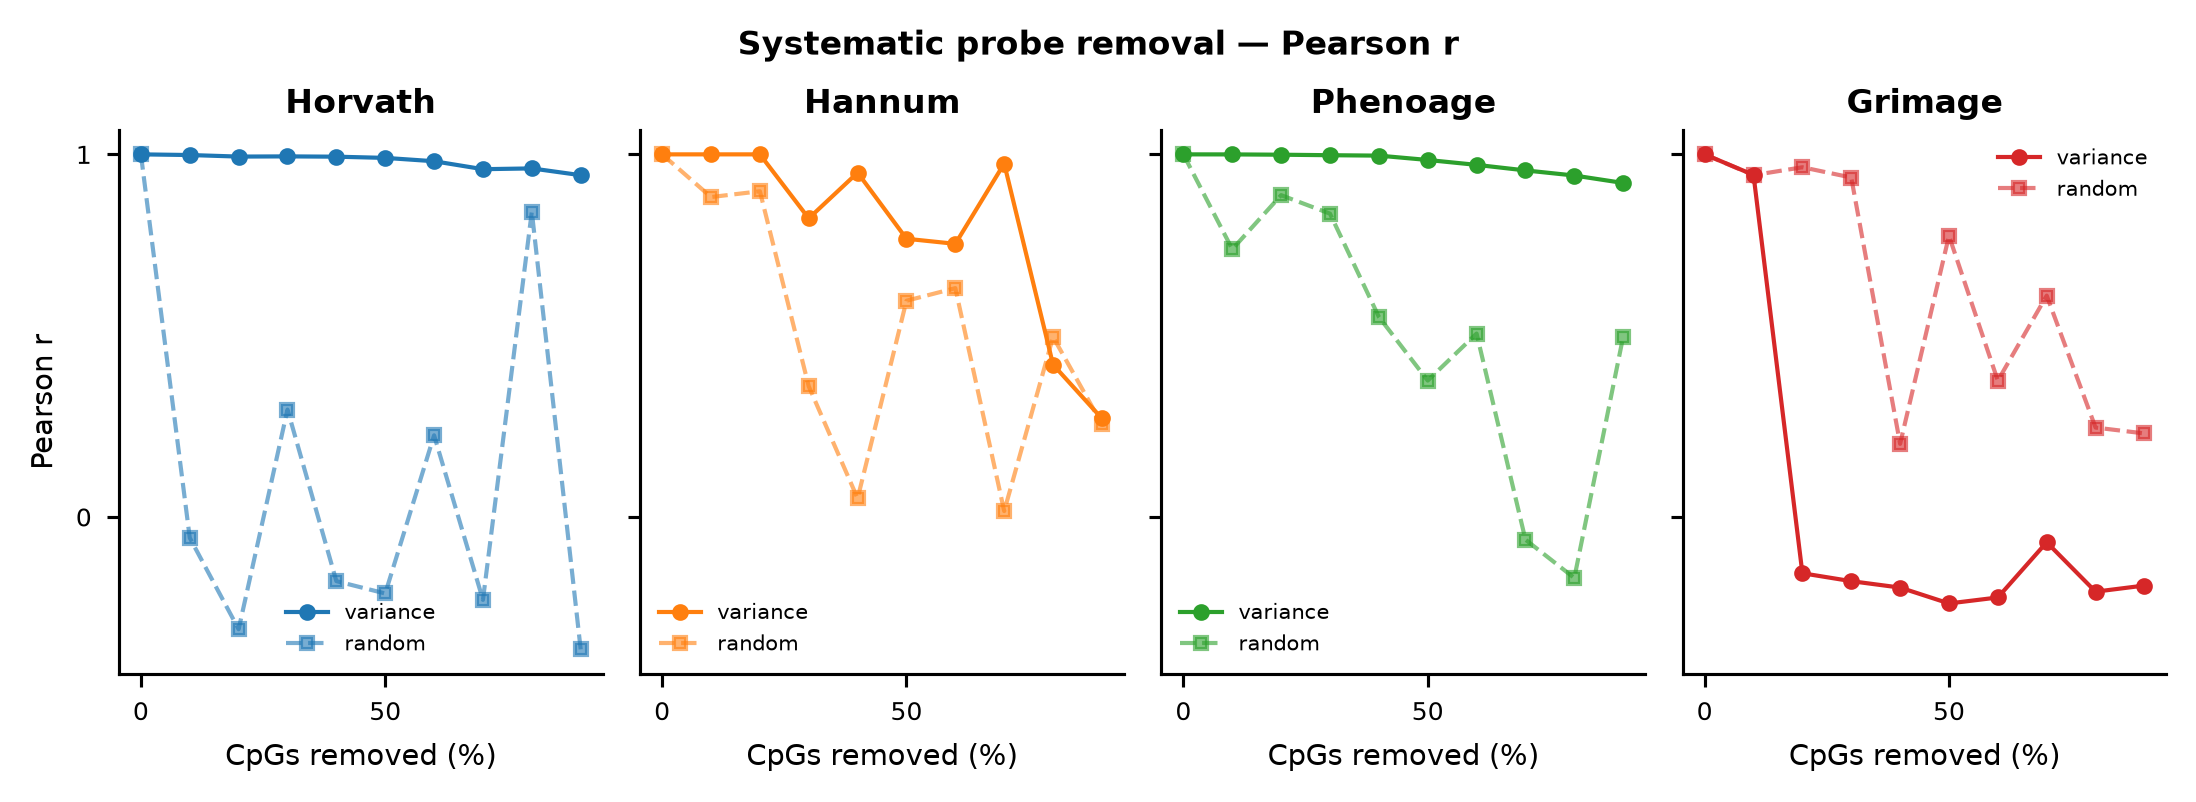

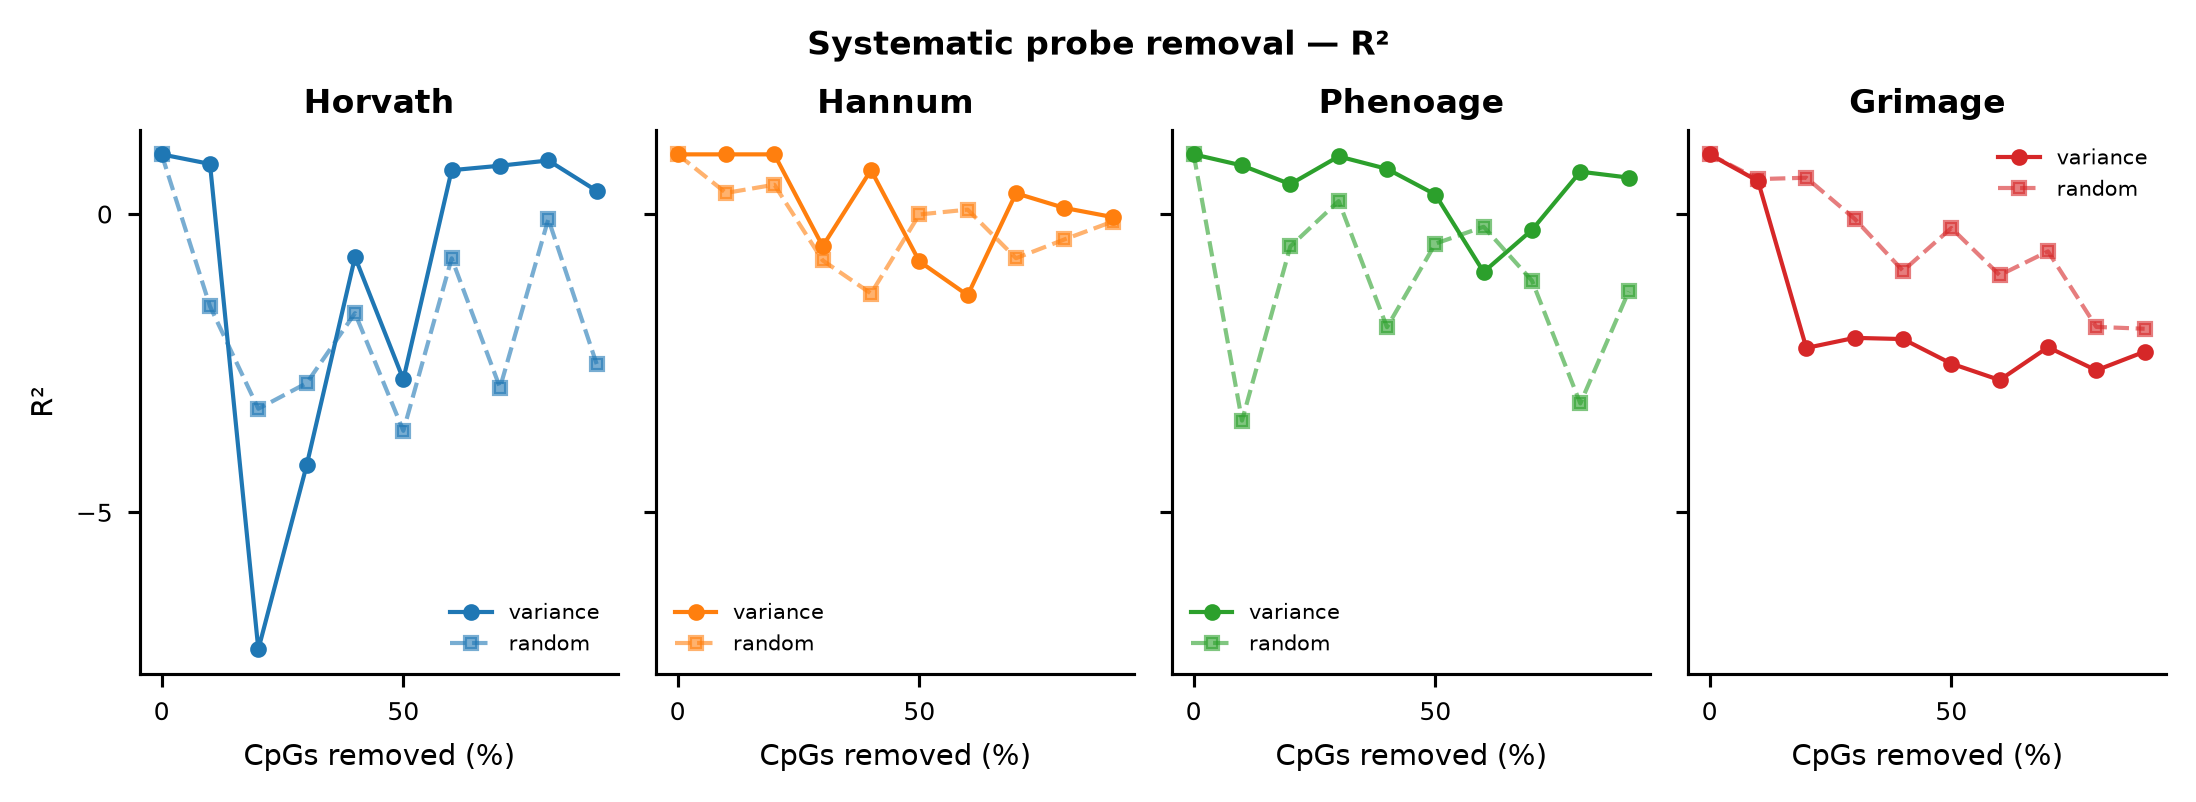

In [20]:
for metric in ("mae", "pearson_r", "r2"):
    fig, axes = plot_systematic_removal_curves(
        systematic_results,
        random_results = mask_results,   # dashed overlay from Analysis 1
        metric         = metric,
        clock_names    = clock_names,
        strategy_label = REMOVAL_STRATEGY,
    )
    if SAVE_DIR:
        fig.savefig(SAVE_DIR / f"systematic_removal_{metric}.pdf")
        fig.savefig(SAVE_DIR / f"systematic_removal_{metric}.png")
    plt.show()

## Removal strategy comparison

All three strategies overlaid per clock. For linear clocks this directly reveals
whether the elastic-net weights concentrate on high-variance probes: if `variance`
and `sequential` produce the same MAE curve, coefficient magnitude matters more
than probe variability.

  variance done
  sequential done
  mean done


KeyError: 'r2'

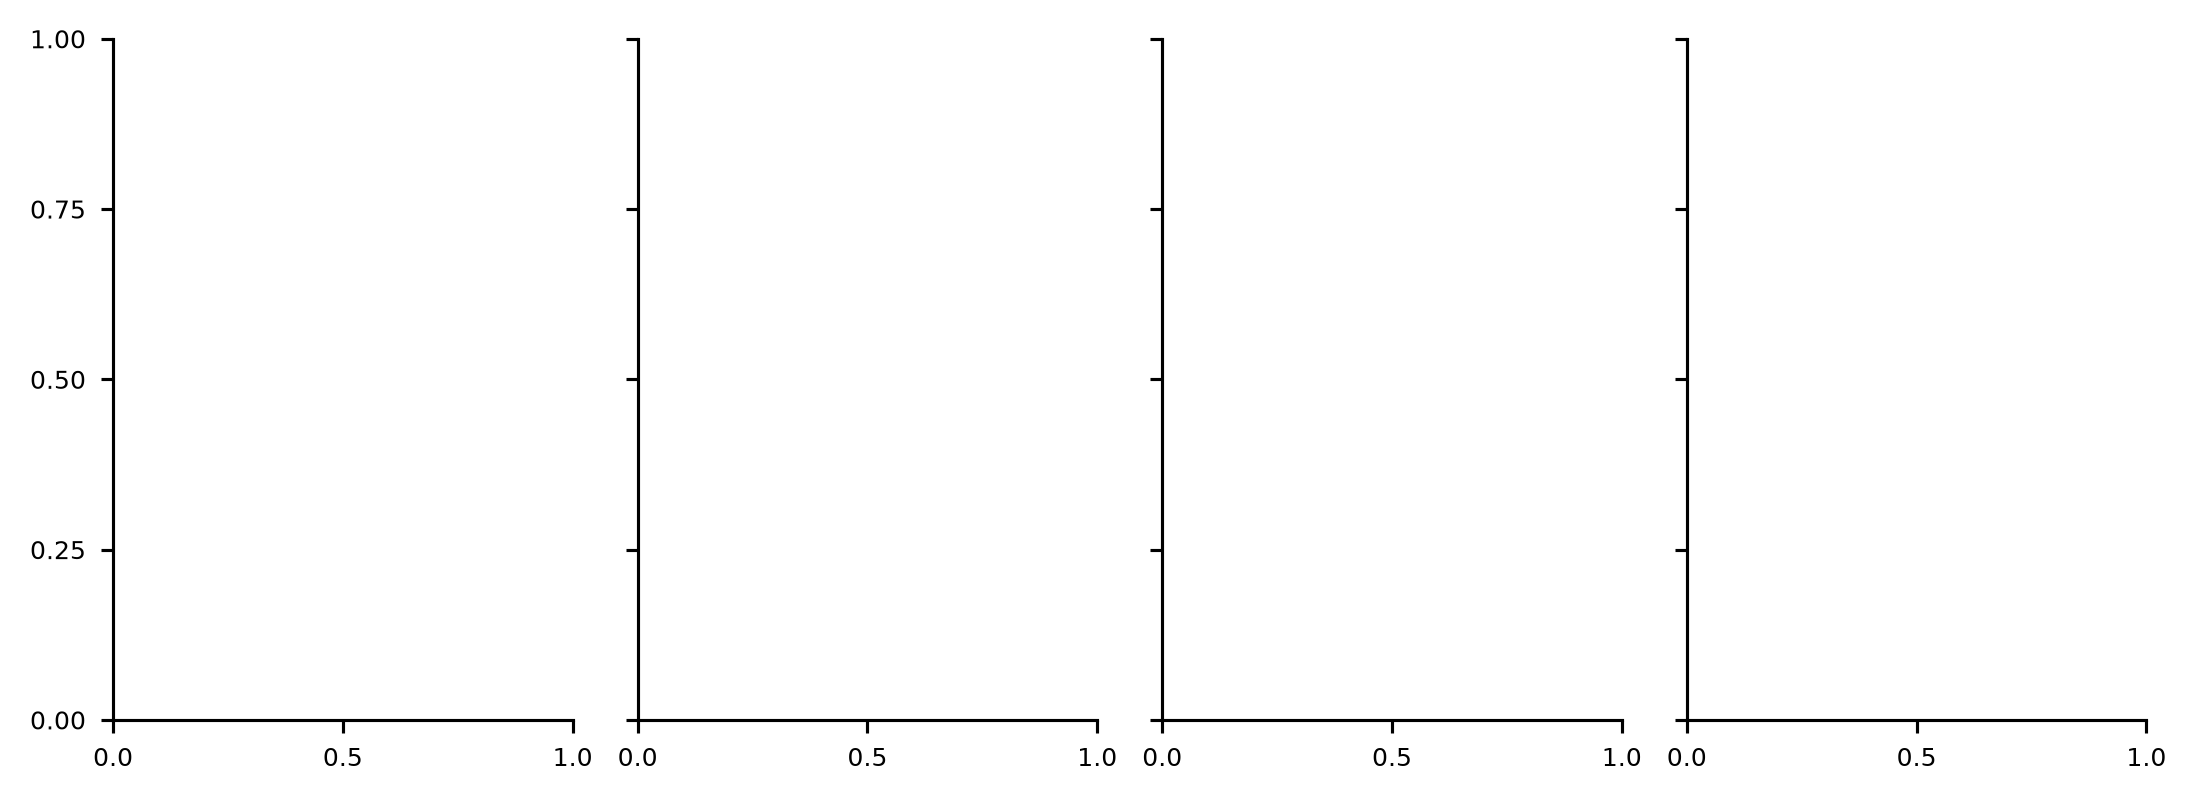

In [22]:
COMPARE_METRIC = "pearson_r"
strategy_dfs   = {}

for strat in ("variance", "sequential", "mean"):
    r_probes, r_label = rank_cpgs_linear(dataset, strategy=strat)
    rows = []
    for frac in REMOVAL_FRACTIONS:
        n_remove      = int(frac * len(r_probes))
        probes_off    = r_probes[:n_remove]
        masked_data   = mask_systematic_cpgs(dataset, probes_off)
        preds, refs = _compare_to_baseline(
            masked_data, baseline_preds, clocks, chron_ages, clock_names,
            save_dir = SAVE_DIR / "strat_tmp",
        )
        for name in clock_names:
            p, t = preds[name], refs[name]
            mae, _, _ = metrics_from_arrays(p, t)
            rows.append(dict(clock=name, removal_frac=frac, mae=mae, n=len(p)))
    strategy_dfs[strat] = (pd.DataFrame(rows), r_label)
    print(f"  {strat} done")

colors  = {"variance": "#2166AC", "sequential": "#4DAC26", "mean": "#D6604D"}
linesty = {"variance": "-",       "sequential": "--",      "mean": "-."}

with plt.rc_context(eu._NM_RC):
    n_c   = len(clock_names)
    fig_w = min(183, 55 * n_c) / 25.4
    fig, axes = plt.subplots(1, n_c, figsize=(fig_w, 65 / 25.4),
                             sharey=True, constrained_layout=True)
    if n_c == 1:
        axes = [axes]

    for ax, name in zip(axes, clock_names):
        for strat, (df, _) in strategy_dfs.items():
            sub = df[df["clock"] == name].sort_values("removal_frac")
            ax.plot(sub["removal_frac"] * 100, sub[COMPARE_METRIC],
                    color=colors[strat], ls=linesty[strat], lw=1.0,
                    marker="o", markersize=2.5, label=strat)
        ax.set_title(eu._clean(name), pad=4, fontweight="bold")
        ax.set_xlabel("CpGs removed (%)")
        ax.set_ylim(bottom=0)
        ax.legend(frameon=False, fontsize=5)

    ylabel = {"mae": "MAE (years)", "pearson_r": "Pearson r", "r2": "R2"}[COMPARE_METRIC]
    axes[0].set_ylabel(ylabel)
    fig.suptitle("Removal strategy comparison", fontsize=8, fontweight="bold")

if SAVE_DIR:
    fig.savefig(SAVE_DIR / f"strategy_comparison_{COMPARE_METRIC}.pdf")
plt.show()

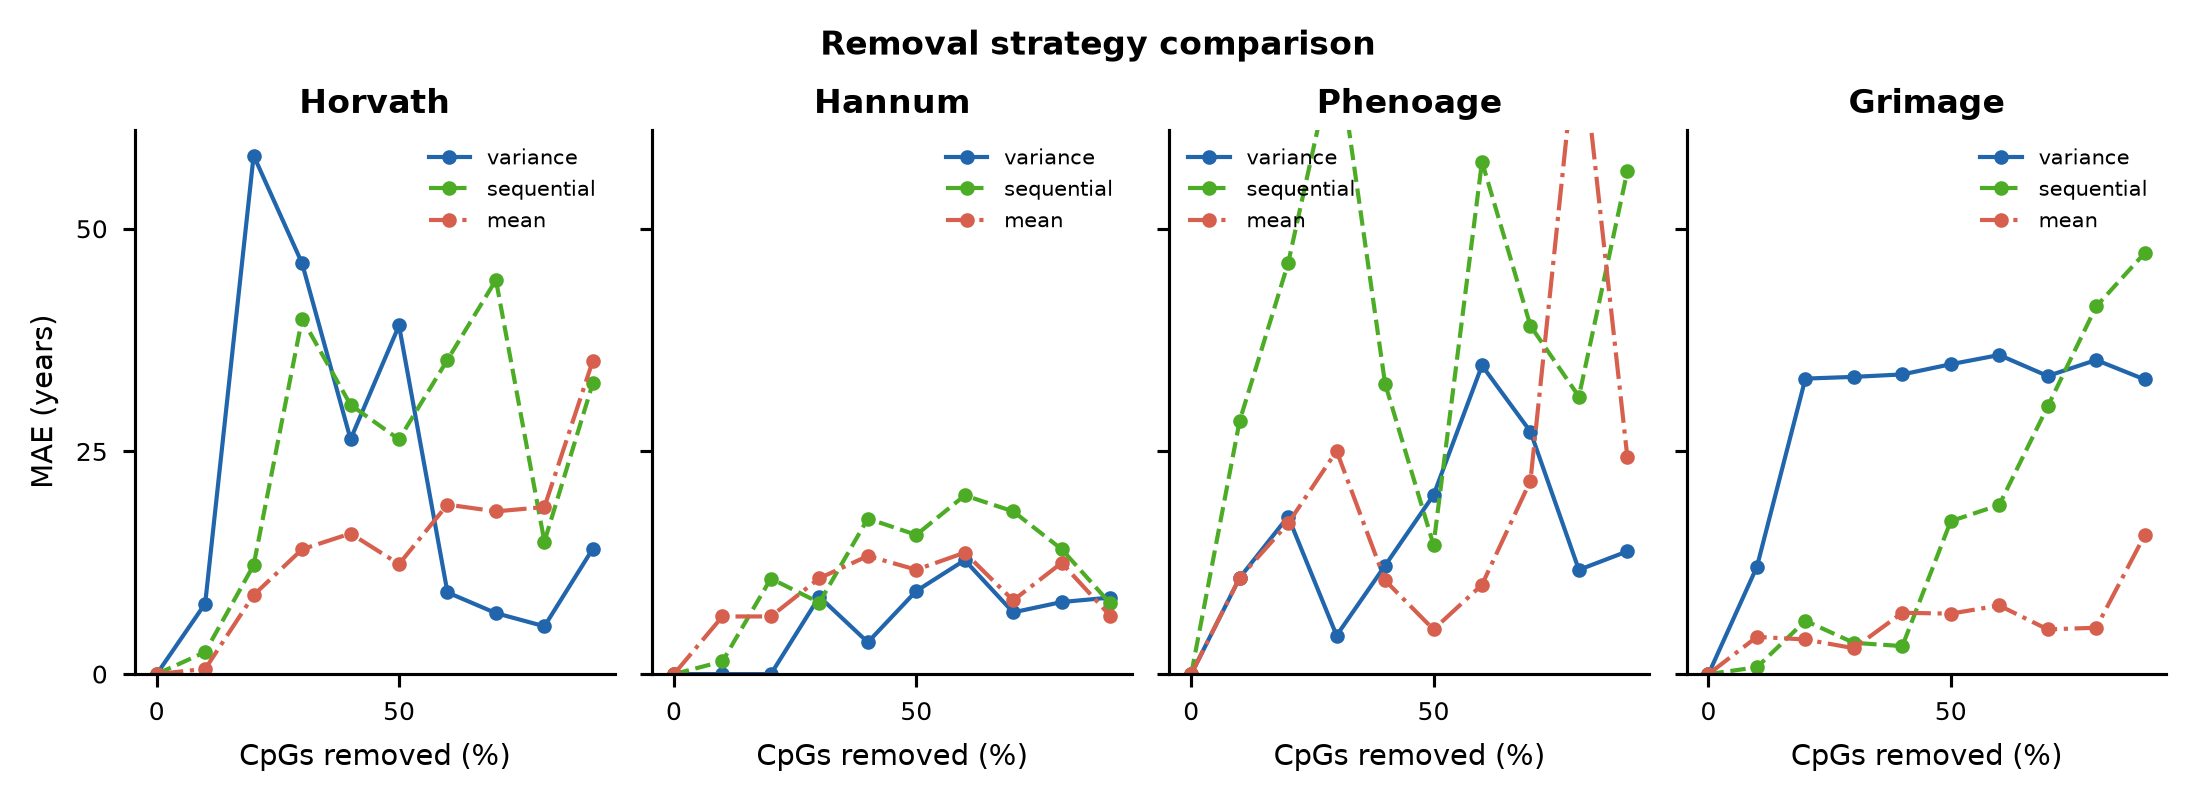

In [29]:
COMPARE_METRIC = "mae"
colors  = {"variance": "#2166AC", "sequential": "#4DAC26", "mean": "#D6604D"}
linesty = {"variance": "-",       "sequential": "--",      "mean": "-."}

with plt.rc_context(eu._NM_RC):
    n_c   = len(clock_names)
    fig_w = min(183, 55 * n_c) / 25.4
    fig, axes = plt.subplots(1, n_c, figsize=(fig_w, 65 / 25.4),
                             sharey=True, constrained_layout=True)
    if n_c == 1:
        axes = [axes]

    for ax, name in zip(axes, clock_names):
        for strat, (df, _) in strategy_dfs.items():
            sub = df[df["clock"] == name].sort_values("removal_frac")
            ax.plot(sub["removal_frac"] * 100, sub[COMPARE_METRIC],
                    color=colors[strat], ls=linesty[strat], lw=1.0,
                    marker="o", markersize=2.5, label=strat)
        ax.set_title(eu._clean(name), pad=4, fontweight="bold")
        ax.set_xlabel("CpGs removed (%)")
        ax.set_ylim(bottom=0)
        ax.legend(frameon=False, fontsize=5)

    ylabel = {"mae": "MAE (years)", "pearson_r": "Pearson r", "r2": "R2"}[COMPARE_METRIC]
    axes[0].set_ylabel(ylabel)
    fig.suptitle("Removal strategy comparison", fontsize=8, fontweight="bold")

if SAVE_DIR:
    fig.savefig(SAVE_DIR / f"strategy_comparison_{COMPARE_METRIC}.pdf")
plt.show()

## Summary: degradation from worst missingness

Compares zero-masking baseline to the heaviest masking/removal level for both
analyses. All metrics are **masked prediction vs. baseline prediction**, so a
positive `delta_mae` means the clock shifted further from its own zero-masking
answer, regardless of how close that answer is to chronological age.

In [30]:
worst_frac = max(MASK_FRACTIONS)

# Baseline here is 0% masking scored against itself -- should be ~0 MAE, r~1
zero_row = mask_results[mask_results["mask_frac"] == 0.0].set_index("clock")
worst_rand = mask_results[mask_results["mask_frac"] == worst_frac].set_index("clock")
worst_syst = systematic_results[systematic_results["removal_frac"] == worst_frac].set_index("clock")

summary = zero_row[["mae", "pearson_r", "r2"]].copy()
summary.columns = [f"zero_mask_{c}" for c in summary.columns]
for metric in ("mae", "pearson_r", "r2"):
    summary[f"rand_{metric}"]       = worst_rand[metric]
    summary[f"syst_{metric}"]       = worst_syst[metric]
    summary[f"delta_rand_{metric}"] = (
        summary[f"rand_{metric}"] - summary[f"zero_mask_{metric}"]
    ).round(3)
    summary[f"delta_syst_{metric}"] = (
        summary[f"syst_{metric}"] - summary[f"zero_mask_{metric}"]
    ).round(3)

print(f"Worst fraction: {worst_frac:.0%} | Removal strategy: {REMOVAL_STRATEGY}")
print("All metrics: masked prediction vs. zero-masking baseline prediction")
display(summary.round(3))

Worst fraction: 90% | Removal strategy: variance
All metrics: masked prediction vs. zero-masking baseline prediction


,zero_mask_mae,zero_mask_pearson_r,zero_mask_r2,rand_mae,syst_mae,delta_rand_mae,delta_syst_mae,rand_pearson_r,syst_pearson_r,delta_rand_pearson_r,delta_syst_pearson_r,rand_r2,syst_r2,delta_rand_r2,delta_syst_r2
clock,,,,,,,,,,,,,,,
horvath_age,0.0,1.0,1.0,31.864,14.075,31.864,14.075,-0.365,0.943,-1.365,-0.057,-2.515,0.389,-3.515,-0.611
hannum_age,0.0,1.0,1.0,6.790,8.593,6.790,8.593,0.256,0.272,-0.744,-0.728,-0.126,-0.051,-1.126,-1.051
phenoage_age,0.0,1.0,1.0,33.307,13.781,33.307,13.781,0.497,0.921,-0.503,-0.079,-1.298,0.610,-2.298,-0.390
grimage_age,0.0,1.0,1.0,33.192,33.083,33.192,33.083,0.230,-0.189,-0.770,-1.189,-1.923,-2.307,-2.923,-3.307
